# Características del terapeuta y predicción de la respuesta top

En este notebook se estudia si el historial de un profesional aporta información para predecir cuál de las respuestas a una pregunta será la más votada.

Los análisis anteriores mostraron que muchos profesionales aparecen en varias preguntas y que no es posible construir una separación estricta entre train y test sin profesionales compartidos manteniendo las preguntas completas.

Se conserva el mismo conjunto de preguntas, el mismo particionado por questionID y la misma semilla utilizados en los experimentos anteriores.

## Punto de partida

Se parte del mismo subconjunto utilizado en los experimentos anteriores: preguntas con al menos dos respuestas y cuyo máximo número de upvotes es mayor que cero.

La variable target identifica como top todas las respuestas que alcanzan el máximo número de upvotes dentro de su pregunta.

Para identificar al profesional se utiliza therapistURL, disponible en todas las respuestas del conjunto filtrado.

In [1]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, StratifiedKFold

RANDOM_STATE = 27

url = (
    "https://huggingface.co/datasets/"
    "nbertagnolli/counsel-chat/raw/main/"
    "20220401_counsel_chat.csv"
)

df = pd.read_csv(url)

df_modelo = df.copy()

In [2]:
# Preguntas con al menos dos respuestas
n_respuestas = (
    df_modelo
    .groupby("questionID")["answerText"]
    .transform("size")
)

df_modelo = df_modelo[
    n_respuestas >= 2
].copy()

# Preguntas con al menos un upvote positivo
max_upvotes = (
    df_modelo
    .groupby("questionID")["upvotes"]
    .transform("max")
)

df_modelo = df_modelo[
    max_upvotes > 0
].copy()

# Respuestas top
df_modelo["target"] = (
    df_modelo["upvotes"]
    == df_modelo.groupby("questionID")["upvotes"].transform("max")
).astype(int)

# Identificador del terapeuta
df_modelo["therapist_id"] = df_modelo["therapistURL"]

In [3]:
print("Preguntas:", df_modelo["questionID"].nunique())
print("Respuestas:", len(df_modelo))
print("Profesionales:", df_modelo["therapist_id"].nunique())
print("therapistURL nulos:", df_modelo["therapist_id"].isna().sum())

Preguntas: 276
Respuestas: 1732
Profesionales: 414
therapistURL nulos: 0


#### Particiones experimentales

Para mantener la comparabilidad con los modelos anteriores, se reproduce el mismo split 80/20 estratificado según el número de respuestas candidatas y la existencia de empate en la respuesta top.

In [4]:
info_preguntas = (
    df_modelo
    .groupby("questionID")
    .agg(
        n_respuestas=("answerText", "size"),
        n_top=("target", "sum")
    )
    .reset_index()
)

info_preguntas["empate"] = (
    info_preguntas["n_top"] > 1
)


def grupo_n_respuestas(n):
    if n == 2:
        return "2"
    elif n == 3:
        return "3"
    elif n <= 5:
        return "4-5"
    elif n <= 10:
        return "6-10"
    else:
        return ">10"


info_preguntas["grupo_respuestas"] = (
    info_preguntas["n_respuestas"]
    .apply(grupo_n_respuestas)
)

info_preguntas["estrato"] = (
    info_preguntas["grupo_respuestas"]
    + "_empate_"
    + info_preguntas["empate"].astype(str)
)

In [5]:
preguntas_train, preguntas_test = train_test_split(
    info_preguntas,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=info_preguntas["estrato"]
)

train_equilibrado = df_modelo[
    df_modelo["questionID"].isin(
        preguntas_train["questionID"]
    )
].copy()

test_equilibrado = df_modelo[
    df_modelo["questionID"].isin(
        preguntas_test["questionID"]
    )
].copy()

print(
    "Preguntas train:",
    train_equilibrado["questionID"].nunique()
)

print(
    "Preguntas test:",
    test_equilibrado["questionID"].nunique()
)

Preguntas train: 220
Preguntas test: 56


In [6]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_splits_equilibrados = []

for train_q_idx, val_q_idx in skf.split(
    preguntas_train,
    preguntas_train["estrato"]
):

    ids_train_fold = set(
        preguntas_train.iloc[train_q_idx]["questionID"]
    )

    ids_val_fold = set(
        preguntas_train.iloc[val_q_idx]["questionID"]
    )

    train_idx = np.where(
        train_equilibrado["questionID"]
        .isin(ids_train_fold)
    )[0]

    val_idx = np.where(
        train_equilibrado["questionID"]
        .isin(ids_val_fold)
    )[0]

    cv_splits_equilibrados.append(
        (train_idx, val_idx)
    )

### Información disponible del terapeuta

Además de therapistURL, utilizado como identificador, el dataset contiene therapistInfo, una breve descripción textual del profesional.

Antes de definir las características del terapeuta, se revisa qué tipo de información contiene esta variable y si presenta una estructura suficientemente homogénea para utilizarla directamente.

In [7]:
info_terapeutas = (
    df_modelo[
        ["therapistURL", "therapistInfo"]
    ]
    .drop_duplicates(subset="therapistURL")
    .copy()
)

info_terapeutas["longitud_info"] = (
    info_terapeutas["therapistInfo"]
    .astype(str)
    .str.len()
)

print(
    "Profesionales:",
    info_terapeutas["therapistURL"].nunique()
)

print(
    "therapistInfo nulos:",
    info_terapeutas["therapistInfo"].isna().sum()
)

display(
    info_terapeutas[
        ["therapistInfo"]
    ].sample(
        min(10, len(info_terapeutas)),
        random_state=27
    )
)

display(
    info_terapeutas["longitud_info"]
    .describe()
    .round(2)
)

Profesionales: 414
therapistInfo nulos: 0


,therapistInfo
226,Victoria HaagFind direction for your life...
862,"Francesca Steele MS, LMHC, CHTsoulspeak wellne..."
273,"Shari PescatorePsychotherapist, Health and Wel..."
1981,Ariel Sheeger“In any given moment we have two ...
3,"Noorayne ChevalierMA, RP, CCC, CCAC, LLP (Mich..."
488,Viktoria IvanovaYou are a warrior! Every day y...
1515,"Zofia Czajkowska, PhD OPQPsychologist in Montreal"
77,Jessica ClineSpecialist in Divorce Recovery
2519,Ilse de LeónYou matter!
38,Kevin MimmsBuilding Better Connections


,longitud_info
count,414.00
mean,54.63
std,29.19
min,10.00
25%,39.00
50%,50.00
75%,64.00
max,238.00


Las descripciones son breves y heterogéneas: combinan nombres, credenciales, especialidades y frases descriptivas. Por tanto, therapistInfo no se incorpora directamente como característica del modelo. El análisis del profesional se centra en variables históricas cuantificables y construidas exclusivamente a partir de los datos de entrenamiento.

## Características históricas del terapeuta

Se estudia si el comportamiento previo de un profesional aporta información sobre la probabilidad de que una nueva respuesta sea la más votada.

Para cada terapeuta se consideran tres características históricas:

- therapist_n_hist: número de respuestas anteriores disponibles;
- therapist_top_rate: proporción de esas respuestas que fueron top;
- therapist_mean_upvotes: media de upvotes obtenida en esas respuestas.

Además, se incluye therapist_seen, que indica si existe historial previo para ese profesional.

Para evitar fuga de información, el historial utilizado para una respuesta nunca incluye información de esa propia respuesta. En validación y test, las características se calculan exclusivamente a partir del conjunto de entrenamiento correspondiente.

#### Historial para las respuestas de entrenamiento

En las respuestas utilizadas para entrenar el modelo se aplica un cálculo *leave-one-out*: al construir las características de una respuesta se excluyen su propio target y sus propios upvotes.

Si el terapeuta no dispone de ninguna otra respuesta, se considera que no tiene historial y se utilizan como referencia los valores globales del resto del conjunto de entrenamiento.

In [8]:
def añadir_historial_loo(datos):
    datos = datos.copy()

    # Estadísticas totales por terapeuta
    stats = (
        datos
        .groupby("therapist_id")
        .agg(
            n_total=("answerText", "size"),
            top_total=("target", "sum"),
            upvotes_total=("upvotes", "sum")
        )
        .reset_index()
    )

    datos = datos.merge(
        stats,
        on="therapist_id",
        how="left"
    )

    # Excluyo la propia respuesta
    datos["therapist_n_hist"] = datos["n_total"] - 1

    top_hist = (
        datos["top_total"]
        - datos["target"]
    )

    upvotes_hist = (
        datos["upvotes_total"]
        - datos["upvotes"]
    )

    tiene_historial = datos["therapist_n_hist"] > 0

    datos["therapist_seen"] = (
        tiene_historial.astype(int)
    )

    # Valores históricos cuando existen respuestas previas
    datos["therapist_top_rate"] = np.where(
        tiene_historial,
        top_hist / datos["therapist_n_hist"],
        np.nan
    )

    datos["therapist_mean_upvotes"] = np.where(
        tiene_historial,
        upvotes_hist / datos["therapist_n_hist"],
        np.nan
    )

    # Referencias globales leave-one-out para terapeutas sin historial
    n = len(datos)

    global_top_loo = (
        datos["target"].sum() - datos["target"]
    ) / (n - 1)

    global_upvotes_loo = (
        datos["upvotes"].sum() - datos["upvotes"]
    ) / (n - 1)

    datos["therapist_top_rate"] = (
        datos["therapist_top_rate"]
        .fillna(global_top_loo)
    )

    datos["therapist_mean_upvotes"] = (
        datos["therapist_mean_upvotes"]
        .fillna(global_upvotes_loo)
    )

    return datos.drop(
        columns=[
            "n_total",
            "top_total",
            "upvotes_total"
        ]
    )

#### Historial para validación y test

En validación y test no se calcula ningún historial utilizando esas propias particiones.

Primero se agrupan únicamente las respuestas del conjunto de entrenamiento por therapist_id y, para cada profesional, se calculan sus estadísticas históricas: número de respuestas, proporción de respuestas top y media de upvotes.

Después, esas estadísticas calculadas en train se asignan a las respuestas del mismo terapeuta en validación o test.

Si un terapeuta no aparece en train, se considera que no tiene historial disponible (therapist_seen = 0) y se utilizan los valores medios globales del conjunto de entrenamiento como referencia..

In [9]:
def añadir_historial_desde_train(
    datos_objetivo,
    datos_train
):
    datos_objetivo = datos_objetivo.copy()

    stats = (
        datos_train
        .groupby("therapist_id")
        .agg(
            therapist_n_hist=("answerText", "size"),
            top_total=("target", "sum"),
            upvotes_total=("upvotes", "sum")
        )
        .reset_index()
    )

    stats["therapist_top_rate"] = (
        stats["top_total"]
        / stats["therapist_n_hist"]
    )

    stats["therapist_mean_upvotes"] = (
        stats["upvotes_total"]
        / stats["therapist_n_hist"]
    )

    datos_objetivo = datos_objetivo.merge(
        stats[
            [
                "therapist_id",
                "therapist_n_hist",
                "therapist_top_rate",
                "therapist_mean_upvotes"
            ]
        ],
        on="therapist_id",
        how="left"
    )

    datos_objetivo["therapist_seen"] = (
        datos_objetivo["therapist_n_hist"]
        .notna()
        .astype(int)
    )

    # Valores de referencia calculados solo con train
    global_top_rate = datos_train["target"].mean()
    global_mean_upvotes = datos_train["upvotes"].mean()

    datos_objetivo["therapist_n_hist"] = (
        datos_objetivo["therapist_n_hist"]
        .fillna(0)
    )

    datos_objetivo["therapist_top_rate"] = (
        datos_objetivo["therapist_top_rate"]
        .fillna(global_top_rate)
    )

    datos_objetivo["therapist_mean_upvotes"] = (
        datos_objetivo["therapist_mean_upvotes"]
        .fillna(global_mean_upvotes)
    )

    return datos_objetivo

#### Construcción y comprobación de las características

Se construyen las características históricas para train y test utilizando las funciones definidas anteriormente. En train se aplica el cálculo leave-one-out y, para test, el historial se obtiene únicamente a partir de train.

A continuación, se revisa la distribución de las características generadas antes de utilizarlas en los experimentos predictivos.

In [10]:
train_terapeutas = añadir_historial_loo(
    train_equilibrado
)

test_terapeutas = añadir_historial_desde_train(
    test_equilibrado,
    train_equilibrado
)

In [11]:
CARACTERISTICAS_TERAPEUTA = [
    "therapist_seen",
    "therapist_n_hist",
    "therapist_top_rate",
    "therapist_mean_upvotes"
]

display(
    train_terapeutas[
        CARACTERISTICAS_TERAPEUTA
    ].describe().round(3)
)

,therapist_seen,therapist_n_hist,therapist_top_rate,therapist_mean_upvotes
count,1427.000,1427.000,1427.000,1427.000
mean,0.882,24.992,0.208,0.644
std,0.322,45.867,0.242,0.755
min,0.000,0.000,0.000,0.000
25%,1.000,1.000,0.000,0.000
50%,1.000,6.000,0.176,0.571
75%,1.000,19.000,0.314,0.719
max,1.000,153.000,1.000,9.000


Las características muestran que la mayoría de las respuestas de entrenamiento pertenecen a profesionales con historial disponible (88,2 %). La cantidad de historial presenta una distribución muy desigual: la mediana es de 6 respuestas previas, mientras que la media asciende a 24,99 y el máximo a 153.

Las tasas históricas de respuestas top y los upvotes medios presentan valores generalmente bajos, en línea con la distribución observada previamente en el dataset.

#### Disponibilidad de historial en test

In [12]:
print(
    "Respuestas de test con terapeuta visto en train:",
    f"{test_terapeutas['therapist_seen'].mean():.2%}"
)

print(
    "Respuestas de test con terapeuta nuevo:",
    f"{1 - test_terapeutas['therapist_seen'].mean():.2%}"
)

Respuestas de test con terapeuta visto en train: 92.46%
Respuestas de test con terapeuta nuevo: 7.54%


El 92,46 % de las respuestas de test pertenecen a terapeutas que ya aparecen en train, mientras que solo el 7,54 % corresponde a terapeutas nuevos. Esto implica que la evaluación en test refleja principalmente el comportamiento del modelo sobre profesionales ya vistos durante el entrenamiento.

## Heurísticas basadas en el historial del terapeuta

Como primera aproximación, se evalúa si algunas características históricas del profesional permiten seleccionar la respuesta top sin entrenar un modelo.

Para cada pregunta se consideran tres reglas:

- Seleccionar la respuesta del terapeuta con mayor proporción histórica de respuestas top.
- Seleccionar la del terapeuta con mayor media histórica de upvotes.
- Seleccionar la del terapeuta con mayor número de respuestas previas.

Cuando varias respuestas obtienen el mismo valor máximo, la Accuracy@1 se calcula como la probabilidad de acertar al elegir aleatoriamente entre las respuestas empatadas.

#### Función de evaluación

In [13]:
def evaluar_heuristica_terapeuta(datos, caracteristica):
    resultados = []
    empates = 0

    for _, grupo in datos.groupby("questionID"):

        max_valor = grupo[caracteristica].max()

        candidatas = grupo[
            grupo[caracteristica] == max_valor
        ]

        if len(candidatas) > 1:
            empates += 1

        # Accuracy esperada si se elige aleatoriamente
        # entre las candidatas empatadas
        resultados.append(
            candidatas["target"].mean()
        )

    accuracy = np.mean(resultados)

    porcentaje_empates = (
        empates
        / datos["questionID"].nunique()
    )

    return accuracy, porcentaje_empates

#### Validación cruzada

En cada fold, las estadísticas históricas de los terapeutas se calculan exclusivamente a partir de las preguntas de entrenamiento del fold y posteriormente se asignan a las respuestas de validación.

De esta forma, la información de validación no interviene en la construcción del historial.

In [14]:
HEURISTICAS_TERAPEUTA = {
    "Mayor tasa histórica de respuestas top":
        "therapist_top_rate",

    "Mayor media histórica de upvotes":
        "therapist_mean_upvotes",

    "Mayor número de respuestas previas":
        "therapist_n_hist"
}

resultados_cv_terapeuta = {
    nombre: []
    for nombre in HEURISTICAS_TERAPEUTA
}

empates_cv_terapeuta = {
    nombre: []
    for nombre in HEURISTICAS_TERAPEUTA
}


for fold, (train_idx, val_idx) in enumerate(
    cv_splits_equilibrados,
    start=1
):

    datos_train_fold = (
        train_equilibrado
        .iloc[train_idx]
        .copy()
    )

    datos_val_fold = (
        train_equilibrado
        .iloc[val_idx]
        .copy()
    )

    # El historial de validación se obtiene
    # únicamente a partir del train del fold
    datos_val_hist = añadir_historial_desde_train(
        datos_val_fold,
        datos_train_fold
    )

    for nombre, caracteristica in HEURISTICAS_TERAPEUTA.items():

        accuracy, porcentaje_empates = (
            evaluar_heuristica_terapeuta(
                datos_val_hist,
                caracteristica
            )
        )

        resultados_cv_terapeuta[nombre].append(
            accuracy
        )

        empates_cv_terapeuta[nombre].append(
            porcentaje_empates
        )

Resumen:

In [15]:
resumen_cv_terapeuta = []

for nombre in HEURISTICAS_TERAPEUTA:

    accuracies = resultados_cv_terapeuta[nombre]
    empates = empates_cv_terapeuta[nombre]

    resumen_cv_terapeuta.append({
        "Heurística": nombre,
        "Accuracy@1 media (%)":
            np.mean(accuracies) * 100,
        "Desv. estándar (%)":
            np.std(accuracies) * 100,
        "Empates medios (%)":
            np.mean(empates) * 100
    })


resumen_cv_terapeuta = pd.DataFrame(
    resumen_cv_terapeuta
)

display(
    resumen_cv_terapeuta.round(2)
)

,Heurística,Accuracy@1 media (%),Desv. estándar (%),Empates medios (%)
0,Mayor tasa histórica de respuestas top,58.03,3.02,5.45
1,Mayor media histórica de upvotes,60.38,4.16,1.36
2,Mayor número de respuestas previas,33.18,6.87,1.36


Las heurísticas basadas en el rendimiento histórico del terapeuta muestran buenos resultados en validación. La media histórica de upvotes obtiene la mayor Accuracy@1 (60,38 %), seguida de la tasa histórica de respuestas top (58,03 %). En cambio, el número de respuestas previas alcanza solo un 33,18 %, por lo que la actividad del profesional por sí sola aporta poca capacidad predictiva. En general, los porcentajes de empate son bajos.

## Regresión logística pairwise con características del terapeuta

Se evalúa si las características históricas del profesional pueden combinarse mediante un modelo sencillo para predecir cuál de dos respuestas obtiene más upvotes.

Para cada par de respuestas de una misma pregunta se utilizan las diferencias entre sus características históricas. Los pares con el mismo número de upvotes se descartan al no existir una preferencia entre ambas respuestas.

Se utilizan como características la cantidad de historial disponible, la tasa histórica de respuestas top y la media histórica de upvotes.

#### Comprobación previa

Compruebo que un terapeuta no tenga varias respuestas dentro de una misma pregunta. Si ocurriera, tendría que ajustar el leave-one-out para excluir la pregunta completa.

In [16]:
respuestas_mismo_terapeuta_pregunta = (
    df_modelo
    .groupby(["questionID", "therapist_id"])
    .size()
)

print(
    "Combinaciones pregunta-terapeuta con más de una respuesta:",
    (respuestas_mismo_terapeuta_pregunta > 1).sum()
)

Combinaciones pregunta-terapeuta con más de una respuesta: 0


#### Construcción de pares

Para cada pregunta se generan todas las parejas posibles de respuestas con distinto número de upvotes.

Las variables del par se construyen como la diferencia entre las características del terapeuta de la respuesta A y las de la respuesta B. Cada pareja se incluye también en el orden inverso, con la etiqueta opuesta.

In [17]:
from itertools import combinations

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

No incluyo therapist_seen porque therapist_n_hist = 0 ya identifica que no existe historial, por lo que sería parcialmente redundante.

In [18]:
CARACTERISTICAS_MODELO_TERAPEUTA = [
    "therapist_n_hist",
    "therapist_top_rate",
    "therapist_mean_upvotes"
]

In [19]:
CARACTERISTICAS_MODELO_TERAPEUTA_2 = [
    "therapist_top_rate",
    "therapist_mean_upvotes"
]

In [20]:
def crear_pares_terapeuta(datos, caracteristicas):
    X = []
    y = []

    for _, grupo in datos.groupby("questionID"):

        for i, j in combinations(grupo.index, 2):

            respuesta_a = grupo.loc[i]
            respuesta_b = grupo.loc[j]

            # Sin preferencia si tienen los mismos upvotes
            if respuesta_a["upvotes"] == respuesta_b["upvotes"]:
                continue

            diferencias = (
                respuesta_a[caracteristicas].astype(float).values
                - respuesta_b[caracteristicas].astype(float).values
            )

            etiqueta = int(
                respuesta_a["upvotes"]
                > respuesta_b["upvotes"]
            )

            # A - B
            X.append(diferencias)
            y.append(etiqueta)

            # B - A
            X.append(-diferencias)
            y.append(1 - etiqueta)

    return np.asarray(X), np.asarray(y)

#### Modelo pairwise

Se utiliza una regresión logística sobre las diferencias entre las características de ambos terapeutas. Las variables se estandarizan antes del entrenamiento para que sus distintas escalas no condicionen los coeficientes del modelo.

In [21]:
def crear_modelo_terapeuta():
    return Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "logistic",
            LogisticRegression(
                max_iter=1000,
                random_state=RANDOM_STATE
            )
        )
    ])

#### Selección de la respuesta top

En evaluación se comparan entre sí todas las respuestas candidatas de una pregunta. Cada comparación otorga una victoria a la respuesta con mayor probabilidad estimada de ser preferida.

La respuesta con mayor número de victorias se selecciona como top. En caso de empate en victorias, se utiliza como desempate la suma de las probabilidades obtenidas en las comparaciones.

In [22]:
def evaluar_top1_terapeuta(
    modelo,
    datos,
    caracteristicas
):
    resultados = []

    for _, grupo in datos.groupby("questionID"):

        indices = list(grupo.index)

        victorias = {
            idx: 0
            for idx in indices
        }

        probabilidades = {
            idx: 0.0
            for idx in indices
        }

        for i, j in combinations(indices, 2):

            a = (
                grupo.loc[i, caracteristicas]
                .astype(float)
                .values
            )

            b = (
                grupo.loc[j, caracteristicas]
                .astype(float)
                .values
            )

            diferencia_ab = (a - b).reshape(1, -1)
            diferencia_ba = (b - a).reshape(1, -1)

            # P(A > B)
            p_ab = modelo.predict_proba(
                diferencia_ab
            )[0, 1]

            # P(B > A)
            p_ba = modelo.predict_proba(
                diferencia_ba
            )[0, 1]

            # Utilizar las dos direcciones
            score_a = (
                p_ab + (1 - p_ba)
            ) / 2

            score_b = 1 - score_a

            probabilidades[i] += score_a
            probabilidades[j] += score_b

            if score_a >= score_b:
                victorias[i] += 1
            else:
                victorias[j] += 1

        seleccionado = max(
            indices,
            key=lambda idx: (
                victorias[idx],
                probabilidades[idx]
            )
        )

        resultados.append(
            grupo.loc[seleccionado, "target"]
        )

    return np.mean(resultados)

#### Validación cruzada

En cada fold, las características históricas de entrenamiento se calculan únicamente con las respuestas del train del fold. Para las respuestas de validación, el historial se obtiene exclusivamente a partir de ese mismo train.

De esta forma, ninguna información de validación interviene en la construcción de las características ni en el entrenamiento del modelo.

In [23]:
resultados_cv_logistic_terapeuta = []

for fold, (train_idx, val_idx) in enumerate(
    cv_splits_equilibrados,
    start=1
):

    datos_train_fold = (
        train_equilibrado
        .iloc[train_idx]
        .copy()
    )

    datos_val_fold = (
        train_equilibrado
        .iloc[val_idx]
        .copy()
    )

    # Historial del train:
    # cada respuesta excluye su propia información
    train_fold_hist = añadir_historial_loo(
        datos_train_fold
    )

    # Historial de validación:
    # calculado únicamente desde train
    val_fold_hist = añadir_historial_desde_train(
        datos_val_fold,
        datos_train_fold
    )

    X_train, y_train = crear_pares_terapeuta(
        train_fold_hist,
        CARACTERISTICAS_MODELO_TERAPEUTA
    )

    modelo = crear_modelo_terapeuta()

    modelo.fit(
        X_train,
        y_train
    )

    accuracy = evaluar_top1_terapeuta(
        modelo,
        val_fold_hist,
        CARACTERISTICAS_MODELO_TERAPEUTA
    )

    resultados_cv_logistic_terapeuta.append(
        accuracy
    )

    print(
        f"Fold {fold}: "
        f"{accuracy:.2%}"
    )

Fold 1: 72.73%
Fold 2: 59.09%
Fold 3: 63.64%
Fold 4: 56.82%
Fold 5: 61.36%


Resumen:

In [24]:
accuracy_cv_terapeuta = np.mean(
    resultados_cv_logistic_terapeuta
)

std_cv_terapeuta = np.std(
    resultados_cv_logistic_terapeuta
)

print(
    "Accuracy@1 CV media:",
    f"{accuracy_cv_terapeuta:.2%}"
)

print(
    "Desviación estándar:",
    f"{std_cv_terapeuta:.2%}"
)

Accuracy@1 CV media: 62.73%
Desviación estándar: 5.49%


La regresión logística pairwise con características del terapeuta obtiene una Accuracy@1 media del 62,73 %, con una desviación estándar del 5,49 %. Supera ligeramente a la mejor heurística basada únicamente en la media histórica de upvotes (60,38 %), lo que indica que combinar varias características del historial del profesional aporta información adicional.

Dado que el número de respuestas previas mostró un rendimiento bajo como heurística individual, se evalúa también una segunda configuración utilizando únicamente la tasa histórica de respuestas top y la media histórica de upvotes.

In [25]:
resultados_comparacion_terapeuta = {}

for nombre_modelo, caracteristicas in {
    "3 características": CARACTERISTICAS_MODELO_TERAPEUTA,
    "2 características": CARACTERISTICAS_MODELO_TERAPEUTA_2
}.items():

    resultados_cv = []

    for fold, (train_idx, val_idx) in enumerate(
        cv_splits_equilibrados,
        start=1
    ):

        datos_train_fold = (
            train_equilibrado
            .iloc[train_idx]
            .copy()
        )

        datos_val_fold = (
            train_equilibrado
            .iloc[val_idx]
            .copy()
        )

        # Historial del train:
        # cada respuesta excluye su propia información
        train_fold_hist = añadir_historial_loo(
            datos_train_fold
        )

        # Historial de validación:
        # calculado únicamente desde train
        val_fold_hist = añadir_historial_desde_train(
            datos_val_fold,
            datos_train_fold
        )

        X_train, y_train = crear_pares_terapeuta(
            train_fold_hist,
            caracteristicas
        )

        modelo = crear_modelo_terapeuta()

        modelo.fit(
            X_train,
            y_train
        )

        accuracy = evaluar_top1_terapeuta(
            modelo,
            val_fold_hist,
            caracteristicas
        )

        resultados_cv.append(
            accuracy
        )

    resultados_comparacion_terapeuta[nombre_modelo] = {
        "Accuracy@1 CV (%)":
            np.mean(resultados_cv) * 100,
        "Desv. estándar (%)":
            np.std(resultados_cv) * 100
    }

pd.DataFrame(
    resultados_comparacion_terapeuta
).T.round(2)

,Accuracy@1 CV (%),Desv. estándar (%)
3 características,62.73,5.49
2 características,62.27,4.45


Ambas configuraciones obtienen resultados muy similares. El modelo con tres características alcanza una Accuracy@1 ligeramente superior (62,73 % frente a 62,27 %), pero la diferencia es pequeña. Se selecciona la configuración de dos características, al ofrecer un rendimiento comparable con menor variabilidad entre folds y una representación más sencilla del historial del terapeuta.

#### Entrenamiento final y evaluación en test

Tras seleccionar mediante validación cruzada la configuración con dos características históricas, se entrena el modelo final utilizando todo el conjunto de entrenamiento.

Las características de test se calculan exclusivamente a partir del historial disponible en train. El conjunto de test se utiliza una única vez para obtener la evaluación final.

In [26]:
CARACTERISTICAS_FINALES_TERAPEUTA = [
    "therapist_top_rate",
    "therapist_mean_upvotes"
]

# Historial para train:
# cada respuesta excluye su propia información
train_final_hist = añadir_historial_loo(
    train_equilibrado
)

# Historial para test:
# calculado únicamente a partir de train
test_final_hist = añadir_historial_desde_train(
    test_equilibrado,
    train_equilibrado
)

CReo pares y entreno:

In [27]:
X_train_final, y_train_final = crear_pares_terapeuta(
    train_final_hist,
    CARACTERISTICAS_FINALES_TERAPEUTA
)

modelo_final_terapeuta = crear_modelo_terapeuta()

modelo_final_terapeuta.fit(
    X_train_final,
    y_train_final
)

Pipeline(steps=[('scaler', StandardScaler()),
                ('logistic',
                 LogisticRegression(max_iter=1000, random_state=27))])

Test:

In [28]:
accuracy_test_terapeuta = evaluar_top1_terapeuta(
    modelo_final_terapeuta,
    test_final_hist,
    CARACTERISTICAS_FINALES_TERAPEUTA
)

print(
    "Accuracy@1 test:",
    f"{accuracy_test_terapeuta:.2%}"
)

Accuracy@1 test: 58.93%


El modelo final obtiene una Accuracy@1 del 58,93 % en test, frente al 62,27 % medio observado en validación cruzada. Aunque el rendimiento disminuye ligeramente, el historial del terapeuta mantiene una señal predictiva relevante sobre datos no utilizados en el entrenamiento.


In [29]:
coeficientes = (
    modelo_final_terapeuta
    .named_steps["logistic"]
    .coef_[0]
)

importancia_terapeuta = pd.DataFrame({
    "Característica": CARACTERISTICAS_FINALES_TERAPEUTA,
    "Coeficiente": coeficientes
})

display(
    importancia_terapeuta
    .sort_values(
        "Coeficiente",
        ascending=False
    )
    .round(3)
)

,Característica,Coeficiente
1,therapist_mean_upvotes,1.017
0,therapist_top_rate,0.204


Ambos coeficientes son positivos, aunque la media histórica de upvotes presenta un peso claramente mayor (1,017) que la tasa histórica de respuestas top (0,204), por lo que es la característica con mayor influencia en este modelo.

## Combinación de características textuales y del terapeuta

Hasta ahora se han estudiado por separado dos fuentes de información: las características del texto de la respuesta y el historial del profesional.

En esta sección se combinan ambas perspectivas en una misma regresión logística pairwise. Se comparan tres configuraciones:

- Características textuales.
- Características históricas del terapeuta.
- Características textuales + historial del terapeuta.

La comparación se realiza primero mediante validación cruzada sobre las mismas particiones utilizadas anteriormente.

#### Características textuales

Se reutilizan las cuatro características textuales empleadas en el cuaderno anterior y las dos características históricas del terapeuta seleccionadas mediante validación cruzada.

A partir de ellas se definen tres configuraciones: solo texto, solo terapeuta y la combinación de ambas fuentes de información.

In [30]:
import re

EXPRESIONES_EMPATIA = [
    "i understand",
    "i'm sorry",
    "i am sorry",
    "it sounds like",
    "that sounds",
    "i hear you",
    "you are not alone",
    "you're not alone",
    "it makes sense",
    "thank you for sharing"
]


def añadir_caracteristicas_textuales(datos):
    datos = datos.copy()

    texto = (
        datos["answerText"]
        .fillna("")
        .astype(str)
        .str.lower()
    )

    datos["longitud"] = texto.str.len()

    datos["freq_therapy"] = (
        texto.str.count(r"\btherapy\b")
    )

    datos["freq_counselor"] = (
        texto.str.count(r"\bcounselor\b")
    )

    patron_empatia = "|".join(
        re.escape(expresion)
        for expresion in EXPRESIONES_EMPATIA
    )

    datos["freq_empatia"] = (
        texto.str.count(patron_empatia)
    )

    return datos

In [31]:
CARACTERISTICAS_TEXTO = [
    "longitud",
    "freq_therapy",
    "freq_counselor",
    "freq_empatia"
]

CARACTERISTICAS_TERAPEUTA_FINAL = [
    "therapist_top_rate",
    "therapist_mean_upvotes"
]

CARACTERISTICAS_COMBINADAS = (
    CARACTERISTICAS_TEXTO
    + CARACTERISTICAS_TERAPEUTA_FINAL
)

#### Comparación mediante validación cruzada

En cada fold se vuelven a construir las características históricas del terapeuta utilizando únicamente los datos de entrenamiento de ese fold.

Después se entrenan tres regresiones logísticas pairwise con la misma configuración, variando únicamente las características utilizadas.

Las funciones pairwise y la regresión logística definidas anteriormente son independientes del tipo de características utilizadas. A partir de esta sección se emplean nombres genéricos, ya que se aplicarán tanto a características textuales como del terapeuta.

In [32]:
crear_pares = crear_pares_terapeuta
evaluar_top1 = evaluar_top1_terapeuta
crear_modelo = crear_modelo_terapeuta

In [33]:
CONFIGURACIONES = {
    "Solo texto": CARACTERISTICAS_TEXTO,
    "Solo terapeuta": CARACTERISTICAS_TERAPEUTA_FINAL,
    "Texto + terapeuta": CARACTERISTICAS_COMBINADAS
}

resultados_cv_combinacion = {
    nombre: []
    for nombre in CONFIGURACIONES
}


for fold, (train_idx, val_idx) in enumerate(
    cv_splits_equilibrados,
    start=1
):

    datos_train_fold = (
        train_equilibrado
        .iloc[train_idx]
        .copy()
    )

    datos_val_fold = (
        train_equilibrado
        .iloc[val_idx]
        .copy()
    )

    # Características textuales
    datos_train_fold = añadir_caracteristicas_textuales(
        datos_train_fold
    )

    datos_val_fold = añadir_caracteristicas_textuales(
        datos_val_fold
    )

    # Historial del terapeuta
    train_fold_hist = añadir_historial_loo(
        datos_train_fold
    )

    val_fold_hist = añadir_historial_desde_train(
        datos_val_fold,
        datos_train_fold
    )

    for nombre, caracteristicas in CONFIGURACIONES.items():

        X_train, y_train = crear_pares(
            train_fold_hist,
            caracteristicas
        )

        modelo = crear_modelo()

        modelo.fit(
            X_train,
            y_train
        )

        accuracy = evaluar_top1(
            modelo,
            val_fold_hist,
            caracteristicas
        )

        resultados_cv_combinacion[nombre].append(
            accuracy
        )

Resumen:

In [34]:
resumen_combinacion = []

for nombre, resultados in resultados_cv_combinacion.items():

    resumen_combinacion.append({
        "Configuración": nombre,
        "Accuracy@1 CV (%)":
            np.mean(resultados) * 100,
        "Desv. estándar (%)":
            np.std(resultados) * 100
    })

resumen_combinacion = pd.DataFrame(
    resumen_combinacion
)

display(
    resumen_combinacion.round(2)
)

,Configuración,Accuracy@1 CV (%),Desv. estándar (%)
0,Solo texto,46.36,6.52
1,Solo terapeuta,62.27,4.45
2,Texto + terapeuta,61.36,4.55


El modelo basado únicamente en el historial del terapeuta obtiene el mejor resultado en validación cruzada (62,27 %). La combinación de texto y terapeuta alcanza un 61,36 %, por lo que añadir las características textuales no aporta una mejora adicional. Además, ambas configuraciones presentan una variabilidad similar entre folds. Por tanto, se mantiene el modelo de solo terapeuta como configuración final.

## Profesionales vistos vs. nuevos

El modelo basado en el historial del terapeuta depende de que exista información previa sobre el profesional. Por ello, se analiza si su rendimiento cambia cuando todos los terapeutas de una pregunta ya han aparecido en train frente a cuando aparece al menos un profesional nuevo.

El análisis se realiza sobre las preguntas completas de test, sin eliminar respuestas ni modificar el conjunto de candidatos.

#### Predicción y disponibilidad de historial por pregunta

Se obtiene la predicción del modelo final para cada pregunta de test y se registra si la respuesta seleccionada es top. Además, se identifica si todos los terapeutas candidatos disponen de historial en train y cuántos profesionales nuevos aparecen en cada pregunta.

In [35]:
def resultados_top1_por_pregunta(
    modelo,
    datos,
    caracteristicas
):
    resultados = []

    for question_id, grupo in datos.groupby("questionID"):

        indices = list(grupo.index)

        victorias = {
            idx: 0
            for idx in indices
        }

        probabilidades = {
            idx: 0.0
            for idx in indices
        }

        for i, j in combinations(indices, 2):

            a = (
                grupo.loc[i, caracteristicas]
                .astype(float)
                .values
            )

            b = (
                grupo.loc[j, caracteristicas]
                .astype(float)
                .values
            )

            diferencia_ab = (a - b).reshape(1, -1)
            diferencia_ba = (b - a).reshape(1, -1)

            p_ab = modelo.predict_proba(
                diferencia_ab
            )[0, 1]

            p_ba = modelo.predict_proba(
                diferencia_ba
            )[0, 1]

            score_a = (
                p_ab + (1 - p_ba)
            ) / 2

            score_b = 1 - score_a

            probabilidades[i] += score_a
            probabilidades[j] += score_b

            if score_a >= score_b:
                victorias[i] += 1
            else:
                victorias[j] += 1

        seleccionado = max(
            indices,
            key=lambda idx: (
                victorias[idx],
                probabilidades[idx]
            )
        )

        resultados.append({
            "questionID": question_id,
            "acierto": grupo.loc[seleccionado, "target"],
            "todos_vistos": bool(
                (grupo["therapist_seen"] == 1).all()
            ),
            "n_terapeutas_nuevos": int(
                (grupo["therapist_seen"] == 0).sum()
            )
        })

    return pd.DataFrame(resultados)

In [36]:
resultados_test_pregunta = resultados_top1_por_pregunta(
    modelo_final_terapeuta,
    test_final_hist,
    CARACTERISTICAS_FINALES_TERAPEUTA
)

resultados_test_pregunta.head()

,questionID,acierto,todos_vistos,n_terapeutas_nuevos
0,3,0,True,0
1,12,0,True,0
2,13,0,False,4
3,14,1,False,6
4,30,1,True,0


#### Rendimiento del modeo final según disponibilidad de historial

El análisis previo mostró que no era posible construir una separación estricta entre train y test sin profesionales compartidos, manteniendo las preguntas completas.

Por ello, una vez evaluado el modelo final, se analiza de forma descriptiva su rendimiento según la disponibilidad de historial de los profesionales en cada pregunta de test:

- Todos vistos: todos los terapeutas aparecen previamente en train.
- Vistos y nuevos: aparecen terapeutas con historial y terapeutas no vistos.
- Todos nuevos: ninguno de los terapeutas aparece en train.

Este análisis no modifica ni vuelve a entrenar el modelo.

In [37]:
disponibilidad_historial = (
    test_final_hist
    .groupby("questionID")
    .agg(
        n_respuestas=("therapist_seen", "size"),
        n_nuevos=("therapist_seen", lambda x: (x == 0).sum())
    )
    .reset_index()
)


def clasificar_historial(fila):
    if fila["n_nuevos"] == 0:
        return "Todos vistos"
    elif fila["n_nuevos"] == fila["n_respuestas"]:
        return "Todos nuevos"
    else:
        return "Vistos y nuevos"


disponibilidad_historial["tipo_historial"] = (
    disponibilidad_historial.apply(
        clasificar_historial,
        axis=1
    )
)

resultados_historial = (
    resultados_test_pregunta[
        ["questionID", "acierto"]
    ]
    .merge(
        disponibilidad_historial[
            ["questionID", "tipo_historial"]
        ],
        on="questionID",
        how="left"
    )
)

In [38]:
orden_grupos = [
    "Todos vistos",
    "Vistos y nuevos",
    "Todos nuevos"
]

comparacion_historial = (
    resultados_historial
    .groupby("tipo_historial")
    .agg(
        preguntas=("questionID", "size"),
        accuracy=("acierto", "mean")
    )
    .reindex(orden_grupos)
    .reset_index()
)

comparacion_historial["preguntas"] = (
    comparacion_historial["preguntas"]
    .fillna(0)
    .astype(int)
)

comparacion_historial["Accuracy@1 (%)"] = (
    comparacion_historial["accuracy"] * 100
)

display(
    comparacion_historial[
        ["tipo_historial", "preguntas", "Accuracy@1 (%)"]
    ].round(2)
)

,tipo_historial,preguntas,Accuracy@1 (%)
0,Todos vistos,44,59.09
1,Vistos y nuevos,12,58.33
2,Todos nuevos,0,NaN


De las 56 preguntas de test, 44 contienen únicamente terapeutas vistos en train y 12 combinan terapeutas vistos y nuevos. No existe ninguna pregunta formada exclusivamente por terapeutas nuevos, lo que es coherente con el fuerte solapamiento entre profesionales observado previamente.  
El modelo obtiene un rendimiento muy similar en los dos grupos evaluables: 59,09 % cuando todos los terapeutas son conocidos y 58,33 % cuando se combinan profesionales vistos y nuevos. Sin embargo, el segundo grupo contiene solo 12 preguntas, por lo que este resultado es menos estable y debe interpretarse con prudencia.
Además, al no existir preguntas con todos los terapeutas nuevos, no puede evaluarse el rendimiento del modelo en un escenario completamente independiente del historial previo.

## Comparación global de resultados

Finalmente, se comparan los principales enfoques evaluados a lo largo de los experimentos.

Se presentan por separado los resultados de validación cruzada y de test. De esta forma, se evita comparar directamente resultados obtenidos en fases distintas del proceso experimental.

#### Comparación en validación cruzada

In [39]:
comparacion_cv = pd.DataFrame({
    "Método": [
        "Respuesta más larga",
        "Más menciones a therapy",
        "Más menciones a counselor",
        "Más referencias a ayuda profesional",
        "Más expresiones de empatía",
        "Regresión logística - texto",
        "BERT pairwise",
        "ModernBERT pairwise",
        "Mayor tasa histórica de respuestas top",
        "Mayor media histórica de upvotes",
        "Mayor número de respuestas previas",
        "Regresión logística - terapeuta",
        "Regresión logística - texto + terapeuta"
    ],

    "Accuracy@1 CV (%)": [
        46.36,
        39.39,
        41.45,
        42.51,
        39.14,
        46.36,
        44.09,
        45.91,
        58.03,
        60.38,
        33.18,
        62.27,
        61.36
    ],

    "Desv. estándar (%)": [
        6.20,
        1.92,
        2.59,
        1.65,
        1.99,
        6.52,
        5.10,
        3.34,
        3.02,
        4.16,
        6.87,
        4.45,
        4.55
    ]
})

display(
    comparacion_cv
    .sort_values("Accuracy@1 CV (%)", ascending=False)
    .reset_index(drop=True)
    .round(2)
)

,Método,Accuracy@1 CV (%),Desv. estándar (%)
0,Regresión logística - terapeuta,62.27,4.45
1,Regresión logística - texto + terapeuta,61.36,4.55
2,Mayor media histórica de upvotes,60.38,4.16
3,Mayor tasa histórica de respuestas top,58.03,3.02
4,Respuesta más larga,46.36,6.20
5,Regresión logística - texto,46.36,6.52
6,ModernBERT pairwise,45.91,3.34
7,BERT pairwise,44.09,5.10
8,Más referencias a ayuda profesional,42.51,1.65
9,Más menciones a counselor,41.45,2.59


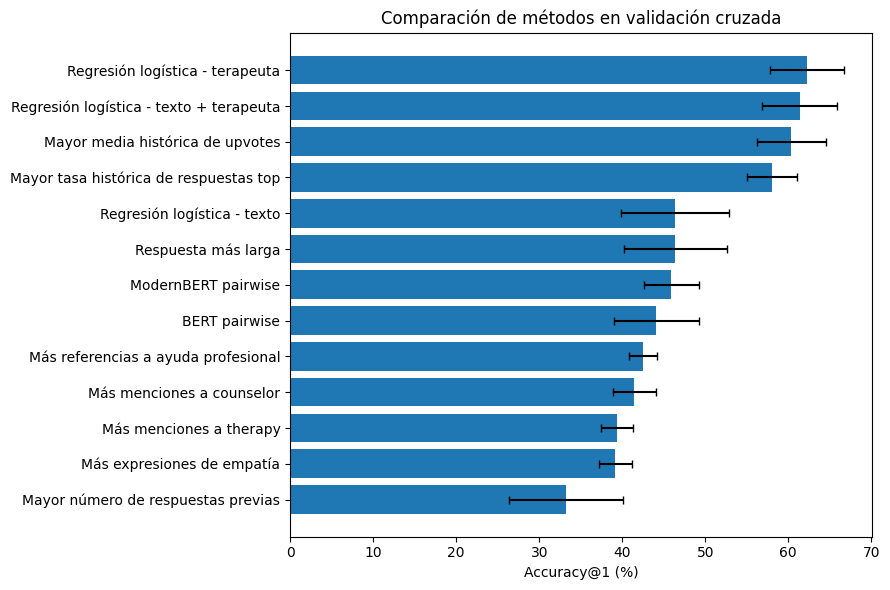

In [40]:
import matplotlib.pyplot as plt

datos_cv = (
    comparacion_cv
    .sort_values("Accuracy@1 CV (%)")
)

plt.figure(figsize=(9, 6))

plt.barh(
    datos_cv["Método"],
    datos_cv["Accuracy@1 CV (%)"],
    xerr=datos_cv["Desv. estándar (%)"],
    capsize=3
)

plt.xlabel("Accuracy@1 (%)")
plt.title("Comparación de métodos en validación cruzada")
plt.tight_layout()
plt.show()

Las características asociadas al historial del terapeuta presentan los mejores resultados en validación cruzada. La regresión logística basada en las dos características históricas seleccionadas alcanza una Accuracy@1 media del 62,27 %, mientras que la combinación con características textuales no produce una mejora adicional (61,36 %).

#### Comparación de los resultados en test

In [41]:
comparacion_test = pd.DataFrame({
    "Método": [
        "Respuesta más larga",
        "Más menciones a therapy",
        "Más menciones a counselor",
        "Más referencias a ayuda profesional",
        "Más expresiones de empatía",
        "Regresión logística - texto",
        "BERT pairwise",
        "ModernBERT pairwise",
        "Heurística léxica derivada de train",
        "Regresión logística - terapeuta"
    ],

    "Accuracy@1 test (%)": [
        39.29,
        39.53,
        40.91,
        43.12,
        32.66,
        44.64,
        37.50,
        33.93,
        47.08,
        58.93
    ]
})

display(
    comparacion_test
    .sort_values("Accuracy@1 test (%)", ascending=False)
    .reset_index(drop=True)
    .round(2)
)

,Método,Accuracy@1 test (%)
0,Regresión logística - terapeuta,58.93
1,Heurística léxica derivada de train,47.08
2,Regresión logística - texto,44.64
3,Más referencias a ayuda profesional,43.12
4,Más menciones a counselor,40.91
5,Más menciones a therapy,39.53
6,Respuesta más larga,39.29
7,BERT pairwise,37.50
8,ModernBERT pairwise,33.93
9,Más expresiones de empatía,32.66


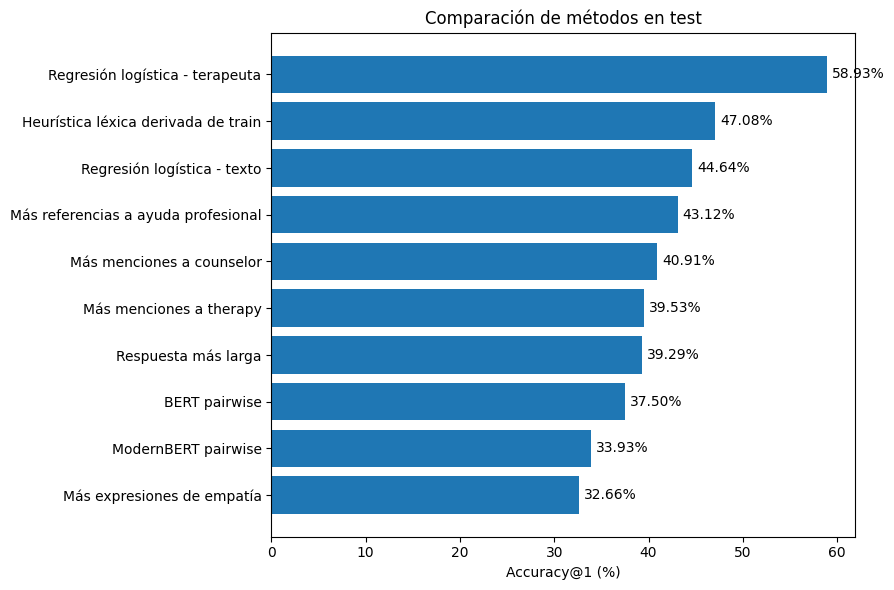

In [42]:
datos_test = (
    comparacion_test
    .sort_values("Accuracy@1 test (%)")
)

plt.figure(figsize=(9, 6))

barras = plt.barh(
    datos_test["Método"],
    datos_test["Accuracy@1 test (%)"]
)

plt.xlabel("Accuracy@1 (%)")
plt.title("Comparación de métodos en test")

for barra, valor in zip(
    barras,
    datos_test["Accuracy@1 test (%)"]
):
    plt.text(
        valor + 0.5,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.2f}%",
        va="center"
    )

plt.tight_layout()
plt.show()

El modelo basado en el historial del terapeuta obtiene el mejor resultado final en test, con una Accuracy@1 del 58,93 %. Entre los métodos basados únicamente en el contenido de las respuestas, el mejor resultado corresponde a la heurística léxica derivada de train (47,08 %).

En conjunto, los resultados muestran que el historial del profesional aporta una señal predictiva especialmente relevante para identificar la respuesta más votada. La incorporación de las características textuales estudiadas no mejora el modelo basado únicamente en esta información histórica.